# Qwen3.5-27B Native vs LoRA Mechanism Discovery

这一步不是再次汇报 test accuracy，而是回答：LoRA 提升后，模型内部对“总重量”“力矩”和“最终答案”的表征在什么深度发生了变化？

[实验设置与运行说明](../../../docs/experiment_notes/07_appendix_lora_training/8f79ceb93e242fa9.md)


In [ ]:
# Notebook utilities: support/visualtorque_checks.py
import base64 as _vt_base64, gzip as _vt_gzip, sys as _vt_sys, types as _vt_types
_vt_source = _vt_gzip.decompress(_vt_base64.b64decode("H4sIAAAAAAACCo1Y647bthL+76dgtziwtLGVTZAGqFs3J8BJkABJESCLoqjXFWiJsnmWElWS2qx7Afo0fbA+SWd4kSnJ23Z/JBLnPvPNcOSLi4vXXDBSHFhxqwltStJIw3ZS3pKS61bQI+kMF9xwpjPyrSS1LJkgUhF23zLFa9YYUrKWNSVrCmS6uLiY8bqVypCqawojpdDh4ED1QfBdeFUsPOmjnlVK1uRgapG1VGmmiKe9uX7/7oM9cSwtNagkkD/A62w2K1lFKgglRxsJ8qSrGYG/ku+ZNmQdjGf6QJ9+8TxJLfUTNwerwolkEiJJ5mo3TwnVINKUgjk9+FdB3MWha24Jbwg3TCWC1ruSrjxnphgtkydXT5+RS4L/pQuym8/Tk4aTR1nXltSwxOpzzihmOtUE+oHduydw1cXnPM8xzDhCLzZ35NWcPBpnYiqf7455Q2uW2JepstjUiQX0AAFyGZFnljw9diZ3R8M0UhMIlj7s8Kg4lvlMBhqpair4z9ZgckdFx0Z+G+WPoRa1vGOtYhW/T3pbqCl/8/LjG3BXsayQdYsxqnny4uvPNi+XP9Dlz1fLL/NtmrxYbeCJLquXy9fbX54/++3X+P3Z1W/AMhQB7fn1q++v8/dv37/6CBaSuWH35jH0EW/mC+LeEOP9S03VbSk/NfMQInpEC5MjNcF/FjY5TK+/lU2IFprs4wHQz5rQpqz0bAsiW8NlQ4U4klvGWt7sCYVY75jSfAfNLqC7u9Y2qoUjGFUMdBQsqakpDhFcbSohDnue7ZXsWt84+KfRBaBars3qydUWKjn/8/c/sKLucPl8te35eeV9JFzjnCEY0bA3eOW1QoN5XhxK7nFjSVvymTc5FI1QYKkD4lDBesTRgx6oMZosUDLd7RKfoAXBimCpCkG1Jvl33Ob0Got1GlRh9EBm85w33OR5opmonHgoaJRn3cEwTdKs5y5kA/UyeXGgChCs16+p0CxKPWjLnDL7GGpvX0CogbaBMGNzC7LZDuVlVWlmkG9zdZ6UgTyM9qTO8N/UDsAaawOtU/GmtDNwfoPYtokZOSiQTgUYwErP+qS4aZlrQ5UxdB9yQ/cLQo1RcWYAEHCOJqGHC8Vbg62jzVGw8VwdmQSxiUWIYmBvami9Huj5Wwtng8LR5Q1EIy9g+0HVDnH9kSthCUYG8wA1DiqextqDEPQHMg4NCN4AfAspurohPsg9M63UUUfbILEqgcPjYIPSZEmeYIc7HdPEeNhltMV1IEmsooXX94gIuFltRhbB0XQ883Ay/t3Me8foHbMQ4bvOIKTBr1uEvUUGPiAw3MzgNd0zmwhAjwH1/cTz+8V62L6D1oz4soqxMnF9H50WQmrmU4dt4aOFyBd+bNo2wakL4kHIpSgCBer1jbpZWR3bMDzhf3sMKv0Q9WMJT0eZC9fIg9n7nLyDVAFQteENxQtCg7oa7iXSaQo5WIC/hehKvC5sVomRVs8S94SSgGe8AlM6C1mwkwMGAdw/3OANerO9STY/ptvLm/TXgzGtfrF6/Hjz443++pvtozTMiMEKMM/+L3mD6TGIYE7+Q54SBqNuiPvW5nYM+egPK8AXxOlpoApdDT1mmJXUE6DZ/LpFYUFq2GLXw4t6mj+7y0LWoo5EtKLTKI9zI7rdhyGE4kyZ+9t/GvPMNzUgtAFcNEXvr+DaRAj6nDS7CvciQ+ASqTmUhZK6E7i2Q9PCRoQlhWLu8EUqrCV2CFRU0WPW68FC2IkTiuL2qOiS1KAU6CEViZOY1sUX1wk4eKArOsF1BNCs19cKNGN0XilMLG/e5uF0O3tVvUmfAm/xfH4g4jTWM+oUKICfo9Mq9zGWvHDT9tTgtnKArWjDG8z2QHc6xtMdzzbIso0Q5GAYEx0ahykdpPO0evzPLX4fDXx01M5cfsd1RwUU+acOr1ekgDnM9uyhjcRxxbsIzvKTsHs4iX9ScH1F28wDkpnjm2yz6QQmeC/4rWpgw0HGGbLP6fBDzKIb8m1pZ+5p5wBSI82V6OCjCOmRtrD+xe47xjROG9yWePX0mcO5ONXiuZJYm+f1SMxhoYNiHjxRJ5dU7eHuury8/YRPYeJAjCjmdx9Tys7vPiVTKl5++lr1to86mIyXD8cW7d7hg/8k6N2dn0MSGHdb6DjZI6OLETa91n4I4/chbEC5/3JJYP4xBcBn5iDL3GmAPHT424K3JRXfw7UlohjPSdlODoOzl4GAbbCQz17Y0yaRep/OhOoXNPv+3/6XDUAZbXWvL+3h0nY7mNOHB2rrXcSTYTLxBL8bB9MKD2FDh8XJats8WW1PhYU+qfp0IVacoaFadxbmmnflDMcmKIqnlPVhTJ+0cUjBJGKXMp+P7Gy6w4yK4XSuvl5JAJId/EL0QIKRKcRoZXxtsTb9VUs24viVuyDAWfzFwm2NxYGLctkqWTAYskJC1sDIEW4gIfoF0n6lgq0ArWidU8dh5u1PVm8/HCGKJvxkBSjMeWuPTmW8L1hryFvL8Uopqc59HzhURh/g6MQ6Vpik/+DhRNFkHDkN4y616jL/lkMloHd8PXAq4V05/xeSBygCsNvhnLu1xX4yoY7wChid92EMxhNqemA65aj5TN8667CHN7C6KraH5Qm/WVvFctU1eQFUkBonIR3JP2gxhq5PrX3/C0ov0eJaFQAA"))
_vt_checks = _vt_types.ModuleType("visualtorque_checks")
exec(compile(_vt_source, "<visualtorque_checks>", "exec"), _vt_checks.__dict__)
_vt_sys.modules["visualtorque_checks"] = _vt_checks
_vt_checks.install_display()
del _vt_source


In [1]:
# Run once. Every later code cell reports progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 16 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 16 tracked cells.


## 1. Reproducibility and test-set scope

先锁定代码、adapter、Dataset v1 和硬件身份。


In [2]:
%%cell_progress 1/16 Mount Drive and select a complete VisualTorque project
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Auditing candidate project roots')
from pathlib import Path
import shutil

PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
REQUIRED_TOOLKIT_PATHS = (
    'pyproject.toml',
    'src/visual_torque_toolkit/__init__.py',
    'src/visual_torque_toolkit/contracts.py',
    'src/visual_torque_toolkit/classify.py',
    'src/visual_torque_toolkit/dataset.py',
    'src/visual_torque_toolkit/edits.py',
    'src/visual_torque_toolkit/generate.py',
    'src/visual_torque_toolkit/prompts.py',
    'src/visual_torque_toolkit/render.py',
    'src/visual_torque_toolkit/splits.py',
    'src/visual_torque_toolkit/world.py',
    'src/visual_torque_toolkit/behavior/__init__.py',
    'src/visual_torque_toolkit/behavior/adapter.py',
    'src/visual_torque_toolkit/behavior/data.py',
    'src/visual_torque_toolkit/behavior/schema.py',
)

def missing_toolkit_paths(project_root):
    toolkit_root = project_root / 'toolkit'
    return [
        relative for relative in REQUIRED_TOOLKIT_PATHS
        if not (toolkit_root / relative).is_file()
    ]

candidate_audit = {
    str(candidate): missing_toolkit_paths(candidate)
    for candidate in PROJECT_CANDIDATES
}
complete_candidates = [
    candidate for candidate in PROJECT_CANDIDATES
    if not candidate_audit[str(candidate)]
]
assert complete_candidates, (
    'No complete toolkit was found. Synchronize the whole toolkit directory. '
    f'Missing-file audit: {candidate_audit}'
)
PROJECT_ROOT = complete_candidates[0]

cell_stage('Copying immutable toolkit source to local SSD')
DRIVE_TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
TOOLKIT_ROOT = Path('/content/visualtorque_toolkit_runtime')
if TOOLKIT_ROOT.exists():
    shutil.rmtree(TOOLKIT_ROOT)
shutil.copytree(DRIVE_TOOLKIT_ROOT, TOOLKIT_ROOT)
assert not [
    relative for relative in REQUIRED_TOOLKIT_PATHS
    if not (TOOLKIT_ROOT / relative).is_file()
]
print('Project:', PROJECT_ROOT)
print('Toolkit runtime:', TOOLKIT_ROOT)


Mount Drive and select a complete VisualTorque project:   0%|          | 0/16 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque
Toolkit runtime: /content/visualtorque_toolkit_runtime


In [3]:
%%cell_progress 2/16 Install and verify the frozen analysis environment
import importlib
import importlib.metadata
import json
import os
import subprocess
import sys

cell_stage('Configuring caches before importing Torch')
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
os.environ.setdefault('HF_HOME', '/content/hf_cache')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

cell_stage('Removing incompatible optional Torch packages')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio', 'torchao'],
    check=False,
)
importlib.invalidate_caches()

cell_stage('Installing pinned model, PEFT, and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    '--upgrade-strategy', 'only-if-needed',
    'transformers==5.14.0', 'peft==0.20.0', 'accelerate>=1.10',
    'sentencepiece', 'protobuf', 'huggingface_hub>=0.34',
    'safetensors', 'tqdm>=4.66', 'scikit-learn>=1.5',
    'scipy>=1.13', 'pandas>=2.2', 'matplotlib>=3.8', 'joblib>=1.4',
])

cell_stage('Importing the immutable local toolkit copy')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if module_name == 'visual_torque_toolkit' or module_name.startswith('visual_torque_toolkit.'):
        del sys.modules[module_name]
importlib.invalidate_caches()

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import visual_torque_toolkit
from IPython.display import display
from peft import PeftModel
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge, RidgeClassifier
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, mean_absolute_error, r2_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

# Qwen3.5 requires both token-type tensors to grow when exact candidate
# scoring appends a literal response prefix.
def append_text_prefix_aligned(self, inputs, prefix):
    if not prefix:
        return inputs
    batch_size = inputs['input_ids'].shape[0]
    prefix_tensor = torch.tensor(
        prefix,
        dtype=inputs['input_ids'].dtype,
        device=inputs['input_ids'].device,
    ).unsqueeze(0).expand(batch_size, -1)
    inputs['input_ids'] = torch.cat((inputs['input_ids'], prefix_tensor), dim=1)
    attention_extension = torch.ones(
        (batch_size, len(prefix)),
        dtype=inputs['attention_mask'].dtype,
        device=inputs['attention_mask'].device,
    )
    inputs['attention_mask'] = torch.cat(
        (inputs['attention_mask'], attention_extension), dim=1
    )
    for key in ('token_type_ids', 'mm_token_type_ids'):
        if key not in inputs:
            continue
        extension = torch.zeros(
            (batch_size, len(prefix)),
            dtype=inputs[key].dtype,
            device=inputs[key].device,
        )
        inputs[key] = torch.cat((inputs[key], extension), dim=1)
    return inputs

HuggingFaceMultimodalAdapter._append_text_prefix = append_text_prefix_aligned
torch.backends.cuda.matmul.allow_tf32 = True
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents
try:
    torchao_version = importlib.metadata.version('torchao')
except importlib.metadata.PackageNotFoundError:
    torchao_version = None
assert torchao_version is None
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('transformers:', importlib.metadata.version('transformers'))
print('peft:', importlib.metadata.version('peft'))
print('Toolkit:', toolkit_path)


Install and verify the frozen analysis environment:   6%|6         | 1/16 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
transformers: 5.14.0
peft: 0.20.0
Toolkit: /content/visualtorque_toolkit_runtime/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/16 Lock hardware, model, adapter, and discovery identities
cell_stage('Checking the 96GB single-GPU runtime')
assert torch.cuda.is_available(), 'Select a GPU runtime.'
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GIB = torch.cuda.get_device_properties(0).total_memory / 2**30
GPU_CAPABILITY = torch.cuda.get_device_capability(0)
assert GPU_MEMORY_GIB >= 88, (GPU_NAME, GPU_MEMORY_GIB)
if GPU_CAPABILITY[0] >= 10:
    cuda_tuple = tuple(int(value) for value in torch.version.cuda.split('.')[:2])
    assert cuda_tuple >= (12, 8), (torch.__version__, torch.version.cuda)

MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
EXPECTED_LAYER_COUNT = 64
LAYER_COUNT = 16
BATCH_SIZE = 2
SHARD_EXAMPLES = 64
SEED = 20260904
PROBE_ALPHA = 100.0
AUDIT_SCENES_PER_STRATUM = 4
DISCOVERY_VERSION = 'v1'

TRAIN_RUN_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_bf16_lora_weight_shortcut_v1'
ADAPTER_DIR = TRAIN_RUN_ROOT / 'adapter_final'
ADAPTER_MANIFEST_PATH = TRAIN_RUN_ROOT / 'ADAPTER_MANIFEST.json'
TRAIN_MANIFEST_PATH = TRAIN_RUN_ROOT / 'manifests' / 'train_manifest.jsonl'
PROTOCOL_PATH = TRAIN_RUN_ROOT / 'frozen_protocol.json'
for required in (
    ADAPTER_DIR / 'adapter_config.json',
    ADAPTER_MANIFEST_PATH,
    TRAIN_MANIFEST_PATH,
    PROTOCOL_PATH,
):
    assert required.is_file(), required

adapter_manifest = json.loads(ADAPTER_MANIFEST_PATH.read_text(encoding='utf-8'))
training_protocol = json.loads(PROTOCOL_PATH.read_text(encoding='utf-8'))
assert adapter_manifest['base_model_id'] == MODEL_ID
assert adapter_manifest['base_model_revision'] == MODEL_REVISION
assert training_protocol['identity']['train_source_split'] == 'probe_train'

OUTPUT_ROOT = (
    PROJECT_ROOT / 'results'
    / f'qwen27b_base_vs_lora_mechanism_discovery_{DISCOVERY_VERSION}'
)
BASE_CAPTURE_DIR = OUTPUT_ROOT / 'native_capture'
LORA_CAPTURE_DIR = OUTPUT_ROOT / 'lora_capture'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
PROBE_DIR = ANALYSIS_DIR / 'frozen_probes'
for directory in (
    OUTPUT_ROOT, BASE_CAPTURE_DIR, LORA_CAPTURE_DIR,
    ANALYSIS_DIR, FIGURE_DIR, PROBE_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

print('GPU:', GPU_NAME, '| memory GiB:', round(GPU_MEMORY_GIB, 1))
print('Frozen adapter:', ADAPTER_DIR)
print('Discovery output:', OUTPUT_ROOT)


Lock hardware, model, adapter, and discovery identities:  12%|#2        | 2/16 [00:00<?, ?cell/s]

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | memory GiB: 95.0
Frozen adapter: /content/drive/MyDrive/VisualTorque/results/qwen27b_bf16_lora_weight_shortcut_v1/adapter_final
Discovery output: /content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_mechanism_discovery_v1


In [5]:
%%cell_progress 4/16 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
SOURCE_DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
DRIVE_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(dataset_path):
    return dataset_path.is_dir() and all(
        (dataset_path / filename).is_file()
        for filename in REQUIRED_DATASET_FILES
    )

if not dataset_complete(SOURCE_DATASET_DIR):
    SOURCE_DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [member for member in bundle.infolist() if not member.is_dir()]
            extraction_root = SOURCE_DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (SOURCE_DATASET_DIR / member.filename).resolve()
                if extraction_root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, SOURCE_DATASET_DIR)
        if not dataset_complete(SOURCE_DATASET_DIR):
            nested = [
                item for item in SOURCE_DATASET_DIR.iterdir()
                if dataset_complete(item)
            ]
            assert len(nested) == 1, nested
            SOURCE_DATASET_DIR = nested[0]
    elif dataset_complete(DRIVE_DATASET_DIR):
        cell_stage('Copying Dataset v1 from Drive')
        shutil.copytree(DRIVE_DATASET_DIR, SOURCE_DATASET_DIR, dirs_exist_ok=True)
    else:
        raise FileNotFoundError(
            'Place dataset_v1.zip or the full dataset_v1 directory under '
            'VisualTorque/data on Drive.'
        )
assert dataset_complete(SOURCE_DATASET_DIR)
print('Source dataset:', SOURCE_DATASET_DIR)


Prepare Dataset v1 on local SSD:  19%|#8        | 3/16 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Source dataset: /content/visualtorque_dataset_v1


In [6]:
%%cell_progress 5/16 Audit test-set coverage without constructing test prompts
cell_stage('Reading immutable dataset metadata')
import hashlib
from collections import Counter, defaultdict

def read_jsonl(file_path):
    with Path(file_path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def json_default(value):
    if isinstance(value, Path):
        return str(value)
    if hasattr(value, 'item'):
        return value.item()
    raise TypeError(f'Object of type {type(value).__name__} is not JSON serializable')

def write_json_atomic(file_path, value):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(
            value, indent=2, ensure_ascii=False, sort_keys=True,
            default=json_default,
        ) + '\n',
        encoding='utf-8',
    )
    temporary.replace(file_path)

def write_jsonl_atomic(file_path, rows):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(
                row, ensure_ascii=False, sort_keys=True, default=json_default
            ) + '\n')
    temporary.replace(file_path)

from visualtorque_checks import sha256_file_by_name as sha256_file

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value}'.encode('utf-8')).hexdigest()

def compare_side(left, right):
    if left > right:
        return 'left'
    if left < right:
        return 'right'
    return 'balanced'

def scene_features(scene):
    left = [stack for stack in scene['stacks'] if stack['side'] == 'left']
    right = [stack for stack in scene['stacks'] if stack['side'] == 'right']
    left_units = sum(int(stack['units']) for stack in left)
    right_units = sum(int(stack['units']) for stack in right)
    left_max_distance = max(int(stack['distance']) for stack in left)
    right_max_distance = max(int(stack['distance']) for stack in right)
    outcome = str(scene['derived']['outcome'])
    weight_cue = compare_side(left_units, right_units)
    if weight_cue == 'balanced':
        relation = 'neutral'
    elif weight_cue == outcome:
        relation = 'aligned'
    else:
        relation = 'conflict'
    structure = scene.get('metadata', {}).get(
        'family',
        'multi_stack' if scene['problem_type'] == 'multi_stack' else 'single_stack',
    )
    return {
        'scene_id': scene['scene_id'],
        'split': scene['split'],
        'structure': structure,
        'problem_type': scene['problem_type'],
        'outcome': outcome,
        'weight_cue': weight_cue,
        'shortcut_relation': relation,
        'left_units': left_units,
        'right_units': right_units,
        'weight_delta': left_units - right_units,
        'left_max_distance': left_max_distance,
        'right_max_distance': right_max_distance,
        'max_distance_delta': left_max_distance - right_max_distance,
        'left_torque': int(scene['derived']['left_torque']),
        'right_torque': int(scene['derived']['right_torque']),
        'net_torque': int(scene['derived']['net_torque']),
        'stack_count': len(scene['stacks']),
        'left_stack_count': len(left),
        'right_stack_count': len(right),
    }

scenes = read_jsonl(SOURCE_DATASET_DIR / 'scenes.jsonl')
questions = read_jsonl(SOURCE_DATASET_DIR / 'questions.jsonl')
pairs = read_jsonl(SOURCE_DATASET_DIR / 'counterfactual_pairs.jsonl')
split_record = json.loads((SOURCE_DATASET_DIR / 'splits.json').read_text(encoding='utf-8'))
scene_by_id = {row['scene_id']: row for row in scenes}
feature_frame = pd.DataFrame([scene_features(scene) for scene in scenes])
test_frame = feature_frame[feature_frame['split'] == 'probe_test'].copy()
assert len(test_frame) == 1007, len(test_frame)

cell_stage('Computing coverage tables')
side_order = ['left', 'balanced', 'right']
test_3x3 = pd.crosstab(
    test_frame['weight_cue'], test_frame['outcome']
).reindex(index=side_order, columns=side_order, fill_value=0)
family_outcome = pd.crosstab(
    test_frame['structure'], test_frame['outcome']
).reindex(columns=side_order, fill_value=0)
family_relation = pd.crosstab(
    test_frame['structure'], test_frame['shortcut_relation']
).reindex(columns=['aligned', 'neutral', 'conflict'], fill_value=0)

all_unit_distance = {
    (int(stack['units']), int(stack['distance']))
    for scene in test_frame['scene_id'].map(scene_by_id)
    for stack in scene['stacks']
}
heldout_pairs = {
    tuple(int(value) for value in item)
    for item in split_record['heldout_unit_distance_combinations']
}
contains_heldout = {}
for scene in scenes:
    contains_heldout[scene['scene_id']] = any(
        (int(stack['units']), int(stack['distance'])) in heldout_pairs
        for stack in scene['stacks']
    )
test_frame['assignment_reason'] = test_frame['scene_id'].map(
    lambda scene_id: 'contains_heldout_combo'
    if contains_heldout[scene_id] else 'multi_structure_holdout_only'
)

def shape_key(scene):
    left = tuple(sorted(
        (int(stack['distance']), int(stack['units']))
        for stack in scene['stacks'] if stack['side'] == 'left'
    ))
    right = tuple(sorted(
        (int(stack['distance']), int(stack['units']))
        for stack in scene['stacks'] if stack['side'] == 'right'
    ))
    return left, right

scene_id_by_shape = {shape_key(scene): scene['scene_id'] for scene in scenes}
split_by_scene_id = {scene['scene_id']: scene['split'] for scene in scenes}
mirror_splits = []
for scene_id in test_frame['scene_id']:
    left, right = shape_key(scene_by_id[scene_id])
    mirror_id = scene_id_by_shape.get((right, left))
    mirror_splits.append(split_by_scene_id.get(mirror_id, 'missing'))
test_frame['mirror_split'] = mirror_splits

test_question_counts = Counter(
    row['question_kind'] for row in questions if row['split'] == 'probe_test'
)
intervention_counts = Counter(
    (row['split'], row['edit_type']) for row in pairs
)
absolute_torque = test_frame['net_torque'].abs()
torque_buckets = {
    'zero': int((absolute_torque == 0).sum()),
    '1_to_5': int(((absolute_torque >= 1) & (absolute_torque <= 5)).sum()),
    '6_to_15': int(((absolute_torque >= 6) & (absolute_torque <= 15)).sum()),
    '16_plus': int((absolute_torque >= 16).sum()),
}

coverage_report = {
    'schema_version': 'visualtorque-test-coverage-audit-1.0',
    'dataset_hashes': {
        name: sha256_file(SOURCE_DATASET_DIR / name)
        for name in sorted(REQUIRED_DATASET_FILES)
    },
    'test_scene_count': int(len(test_frame)),
    'outcomes': {key: int(value) for key, value in test_frame['outcome'].value_counts().items()},
    'structures': {key: int(value) for key, value in test_frame['structure'].value_counts().items()},
    'problem_types': {key: int(value) for key, value in test_frame['problem_type'].value_counts().items()},
    'weight_cues': {key: int(value) for key, value in test_frame['weight_cue'].value_counts().items()},
    'shortcut_relations': {key: int(value) for key, value in test_frame['shortcut_relation'].value_counts().items()},
    'stack_counts': {str(key): int(value) for key, value in test_frame['stack_count'].value_counts().items()},
    'side_stack_patterns': {
        f'{left}|{right}': int(value)
        for (left, right), value in test_frame.groupby(
            ['left_stack_count', 'right_stack_count']
        ).size().items()
    },
    'net_torque': {
        'minimum': int(test_frame['net_torque'].min()),
        'maximum': int(test_frame['net_torque'].max()),
        'unique_values': int(test_frame['net_torque'].nunique()),
        'absolute_buckets': torque_buckets,
    },
    'heldout_unit_distance_combinations': sorted([list(item) for item in heldout_pairs]),
    'unit_distance_pairs_present_in_test': sorted([list(item) for item in all_unit_distance]),
    'assignment_reasons': {
        key: int(value) for key, value in test_frame['assignment_reason'].value_counts().items()
    },
    'mirror_split': {
        key: int(value) for key, value in test_frame['mirror_split'].value_counts().items()
    },
    'test_question_kinds': dict(sorted(test_question_counts.items())),
    'intervention_split_by_edit_type': {
        f'{split}|{edit}': int(value)
        for (split, edit), value in sorted(intervention_counts.items())
    },
    'weight_cue_by_outcome': {
        cue: {outcome: int(test_3x3.loc[cue, outcome]) for outcome in side_order}
        for cue in side_order
    },
    'scope_judgment': {
        'complete_within': (
            'Dataset v1 bounded synthetic generator: units 1-5, distances 1-6, '
            'one or two stacks per side, fixed render style.'
        ),
        'not_complete_for': (
            'real-world visual robustness, new render styles, clutter, occlusion, '
            'continuous quantities, longer stacks/distances, multilingual prompts, '
            'or unrestricted balance-scale reasoning.'
        ),
        'current_accuracy_eval_used_only': 'outcome questions; numeric and intervention records remain unevaluated',
    },
}
write_json_atomic(ANALYSIS_DIR / 'test_set_coverage_audit.json', coverage_report)
test_frame.to_csv(ANALYSIS_DIR / 'test_scene_coverage_table.csv', index=False)

print('Test scenes:', len(test_frame))
print('Outcome counts:', coverage_report['outcomes'])
print('Structure counts:', coverage_report['structures'])
print('Shortcut relation:', coverage_report['shortcut_relations'])
print('Torque buckets:', torque_buckets)
print('Assignment reasons:', coverage_report['assignment_reasons'])
print('Mirror split:', coverage_report['mirror_split'])
print('Test question kinds:', coverage_report['test_question_kinds'])
display(test_3x3)
display(family_outcome)
display(family_relation)
print(
    'Conclusion: broad compositional coverage inside the bounded synthetic world, '
    'but not an exhaustive or real-world-complete test set.'
)


Audit test-set coverage without constructing test prompts:  25%|##5       | 4/16 [00:00<?, ?cell/s]

Test scenes: 1007
Outcome counts: {'left': 491, 'right': 475, 'balanced': 41}
Structure counts: {'multi_stack': 683, 'single_stack': 324}
Shortcut relation: {'aligned': 660, 'neutral': 176, 'conflict': 171}
Torque buckets: {'zero': 41, '1_to_5': 293, '6_to_15': 483, '16_plus': 190}
Assignment reasons: {'contains_heldout_combo': 941, 'multi_structure_holdout_only': 66}
Mirror split: {'probe_test': 943, 'probe_train': 55, 'probe_dev': 9}
Test question kinds: {'left_distance': 324, 'left_torque': 1007, 'left_units': 1007, 'net_torque': 1007, 'outcome': 6042, 'right_distance': 324, 'right_torque': 1007, 'right_units': 1007, 'total_units': 1007}


outcome,left,balanced,right
weight_cue,,,
left,335,11,71
balanced,81,16,79
right,75,14,325


outcome,left,balanced,right
structure,,,
multi_stack,338,23,322
single_stack,153,18,153


shortcut_relation,aligned,neutral,conflict
structure,,,
multi_stack,450,116,117
single_stack,210,60,54


Conclusion: broad compositional coverage inside the bounded synthetic world, but not an exhaustive or real-world-complete test set.


## 2. Freeze a train/dev-only discovery manifest

每个 scene 只选一个 A/B/C 映射，且在 split × outcome × weight cue × structure 内平衡 gold label。


In [7]:
%%cell_progress 6/16 Build the train/dev-only frozen discovery manifest
cell_stage('Constructing image-rule outcome examples from train/dev only')
discovery_config = BehaviorRunConfig(
    dataset_dir=SOURCE_DATASET_DIR,
    output_dir=OUTPUT_ROOT / '_unused_behavior_config',
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    splits=('probe_train', 'probe_dev'),
    batch_size=BATCH_SIZE,
    seed=SEED,
)
all_discovery_examples = list(load_behavior_examples(discovery_config))
assert all_discovery_examples
assert all(example.split in {'probe_train', 'probe_dev'} for example in all_discovery_examples)
assert not any(example.split == 'probe_test' for example in all_discovery_examples)

examples_by_scene = defaultdict(list)
for example in all_discovery_examples:
    examples_by_scene[example.scene_id].append(example)
assert all(len(rows) == 6 for rows in examples_by_scene.values())
assert set(examples_by_scene) == set(
    feature_frame.loc[
        feature_frame['split'].isin(['probe_train', 'probe_dev']), 'scene_id'
    ]
)

train_manifest_rows = read_jsonl(TRAIN_MANIFEST_PATH)
sft_seen_scene_ids = {row['scene_id'] for row in train_manifest_rows}
assert sft_seen_scene_ids <= set(
    feature_frame.loc[feature_frame['split'] == 'probe_train', 'scene_id']
)
assert not sft_seen_scene_ids & set(
    feature_frame.loc[feature_frame['split'] == 'probe_dev', 'scene_id']
)

cell_stage('Choosing one label-balanced permutation per scene')
eligible_features = feature_frame[
    feature_frame['split'].isin(['probe_train', 'probe_dev'])
].copy()
main_examples = []
main_manifest = []
stratum_columns = ['split', 'outcome', 'weight_cue', 'structure']
for stratum, group in eligible_features.groupby(stratum_columns, sort=True):
    ordered = group.sort_values(
        'scene_id', key=lambda column: column.map(stable_key)
    ).reset_index(drop=True)
    for index, row in ordered.iterrows():
        desired_label = ('A', 'B', 'C')[index % 3]
        candidates = [
            example for example in examples_by_scene[row['scene_id']]
            if example.gold_label == desired_label
        ]
        assert len(candidates) == 2
        chosen = sorted(
            candidates, key=lambda example: stable_key(example.question_id)
        )[0]
        main_examples.append(chosen)
        main_manifest.append({
            'role': 'main',
            'example_id': chosen.example_id,
            'question_id': chosen.question_id,
            'scene_id': chosen.scene_id,
            'split': chosen.split,
            'gold_label': chosen.gold_label,
            'seen_in_sft': chosen.scene_id in sft_seen_scene_ids,
            **{
                key: row[key].item() if hasattr(row[key], 'item') else row[key]
                for key in (
                    'structure', 'problem_type', 'outcome', 'weight_cue',
                    'shortcut_relation', 'left_units', 'right_units', 'weight_delta',
                    'left_max_distance', 'right_max_distance', 'max_distance_delta',
                    'left_torque', 'right_torque', 'net_torque', 'stack_count',
                )
            },
        })

cell_stage('Adding all six permutations for a small invariance audit')
audit_scene_ids = []
for stratum, group in eligible_features.groupby(
    ['split', 'shortcut_relation', 'structure'], sort=True
):
    ordered_ids = sorted(group['scene_id'], key=stable_key)
    audit_scene_ids.extend(ordered_ids[:AUDIT_SCENES_PER_STRATUM])
audit_scene_ids = sorted(set(audit_scene_ids), key=stable_key)

example_by_id = {example.example_id: example for example in main_examples}
for scene_id in audit_scene_ids:
    for example in examples_by_scene[scene_id]:
        example_by_id.setdefault(example.example_id, example)
discovery_examples = sorted(example_by_id.values(), key=lambda example: stable_key(example.example_id))

main_ids = {example.example_id for example in main_examples}
discovery_manifest = []
features_by_scene = eligible_features.set_index('scene_id').to_dict(orient='index')
for example in discovery_examples:
    row = features_by_scene[example.scene_id]
    discovery_manifest.append({
        'role': 'main+permutation_audit' if example.example_id in main_ids and example.scene_id in audit_scene_ids
                else 'main' if example.example_id in main_ids else 'permutation_audit',
        'example_id': example.example_id,
        'question_id': example.question_id,
        'scene_id': example.scene_id,
        'split': example.split,
        'gold_label': example.gold_label,
        'seen_in_sft': example.scene_id in sft_seen_scene_ids,
        **row,
    })

assert len(main_examples) == 1093, len(main_examples)
assert len({example.scene_id for example in main_examples}) == 1093
assert len(discovery_examples) == len(main_examples) + 5 * len(audit_scene_ids)
assert all(example.split != 'probe_test' for example in discovery_examples)
assert max(
    pd.DataFrame(main_manifest).groupby(stratum_columns)['gold_label']
    .value_counts().unstack(fill_value=0)
    .apply(lambda row: row.max() - row.min(), axis=1)
) <= 1

DISCOVERY_MANIFEST_PATH = OUTPUT_ROOT / 'discovery_manifest.jsonl'
write_jsonl_atomic(DISCOVERY_MANIFEST_PATH, discovery_manifest)
write_json_atomic(OUTPUT_ROOT / 'discovery_design.json', {
    'schema_version': 'qwen27b-base-lora-mechanism-discovery-design-1.0',
    'allowed_model_prompt_splits': ['probe_train', 'probe_dev'],
    'probe_test_model_prompts': 0,
    'main_scene_count': len(main_examples),
    'probe_train_main_scenes': sum(example.split == 'probe_train' for example in main_examples),
    'probe_dev_main_scenes': sum(example.split == 'probe_dev' for example in main_examples),
    'sft_seen_train_scenes': len(sft_seen_scene_ids),
    'permutation_audit_scene_count': len(audit_scene_ids),
    'capture_example_count_per_model': len(discovery_examples),
    'main_permutation_policy': 'gold-label balanced within split/outcome/weight-cue/structure strata',
    'selection_policy': 'fit probe_train, select on probe_dev, never select on probe_test',
})
print('Main train/dev scenes:', len(main_examples))
print('SFT-seen train scenes:', len(sft_seen_scene_ids))
print('Permutation-audit scenes:', len(audit_scene_ids))
print('Forward-pass examples per model:', len(discovery_examples))
display(pd.crosstab(
    pd.DataFrame(main_manifest)['split'],
    pd.DataFrame(main_manifest)['gold_label'],
))


Build the train/dev-only frozen discovery manifest:  31%|###1      | 5/16 [00:00<?, ?cell/s]

Main train/dev scenes: 1093
SFT-seen train scenes: 290
Permutation-audit scenes: 48
Forward-pass examples per model: 1333


gold_label,A,B,C
split,,,
probe_dev,41,37,30
probe_train,334,328,323


## 3. Capture identical native and LoRA residual states

先对原生 checkpoint 做一次完整捕获，再验证保存的 LoRA 文件哈希并只读挂载 adapter，复用完全相同的 manifest。


In [8]:
%%cell_progress 7/16 Load native Qwen and resolve identical decoder depths
cell_stage('Loading the pinned BF16 base checkpoint')
adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=MODEL_DTYPE,
    device_map='cuda:0',
)
adapter.model.eval()
assert not hasattr(adapter.model, 'peft_config'), 'Base run unexpectedly contains PEFT.'
for parameter in adapter.model.parameters():
    parameter.requires_grad_(False)

def discover_decoder_layers(model):
    candidates = [
        (name, module)
        for name, module in model.named_modules()
        if (
            isinstance(module, torch.nn.ModuleList)
            and len(module) == EXPECTED_LAYER_COUNT
            and name.endswith('language_model.layers')
        )
    ]
    if not candidates:
        candidates = [
            (name, module)
            for name, module in model.named_modules()
            if isinstance(module, torch.nn.ModuleList) and len(module) == EXPECTED_LAYER_COUNT
        ]
    if not candidates:
        available = [
            (name, len(module))
            for name, module in model.named_modules()
            if isinstance(module, torch.nn.ModuleList)
        ]
        raise RuntimeError(f'Could not find the 64 decoder layers. Candidates: {available}')
    candidates.sort(key=lambda item: (item[0].count('.'), len(item[0])))
    return candidates[0]

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
layer_indices = sorted(set(
    int(round(value))
    for value in torch.linspace(
        0, len(DECODER_LAYERS) - 1, steps=LAYER_COUNT
    ).tolist()
))
assert len(layer_indices) == LAYER_COUNT, layer_indices
normalized_depths = [(index + 1) / len(DECODER_LAYERS) for index in layer_indices]
print('Base model class:', type(adapter.model).__name__)
print('Layer path:', LAYER_PATH)
print('Selected layer indices:', layer_indices)
print('Normalized depths:', [round(value, 4) for value in normalized_depths])


Load native Qwen and resolve identical decoder depths:  38%|###7      | 6/16 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

Base model class: Qwen3_5ForConditionalGeneration
Layer path: model.language_model.layers
Selected layer indices: [0, 4, 8, 13, 17, 21, 25, 29, 34, 38, 42, 46, 50, 55, 59, 63]
Normalized depths: [0.0156, 0.0781, 0.1406, 0.2188, 0.2812, 0.3438, 0.4062, 0.4688, 0.5469, 0.6094, 0.6719, 0.7344, 0.7969, 0.875, 0.9375, 1.0]


In [9]:
%%cell_progress 8/16 Define exact-score activation capture and resumable shards
cell_stage('Indexing physical targets and prompts')
from datetime import datetime, timezone

manifest_by_example = {row['example_id']: row for row in discovery_manifest}

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        tensor = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        tensor = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(output.last_hidden_state):
        tensor = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported decoder-layer output: {type(output).__name__}')
    if tensor.ndim != 3:
        raise ValueError(f'Expected [batch, sequence, hidden], got {tuple(tensor.shape)}')
    return tensor

def capture_activation_batch(examples):
    if not examples:
        raise ValueError('capture batch must not be empty')
    if any(example.labels != examples[0].labels for example in examples):
        raise ValueError('all examples in a batch must use identical labels')
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('This notebook requires exact single-token A/B/C scoring.')
    fixed_prefix, token_by_label = plan
    labels = list(examples[0].labels)
    inputs = adapter._append_text_prefix(
        adapter._to_device(
            adapter._template(
                [example.messages() for example in examples],
                add_generation_prompt=True,
            )
        ),
        fixed_prefix,
    )
    mask = inputs['attention_mask'].bool()
    positions = (
        mask.long()
        * torch.arange(mask.shape[1], device=mask.device).unsqueeze(0)
    ).max(dim=1).values
    rows = torch.arange(len(examples), device=mask.device)
    captured = {}
    handles = []
    for layer_index in layer_indices:
        def hook(_module, _inputs, output, selected_layer=layer_index):
            hidden = output_hidden_tensor(output)
            captured[selected_layer] = hidden[rows, positions, :].detach().to(
                device='cpu', dtype=torch.float16
            )
        handles.append(DECODER_LAYERS[layer_index].register_forward_hook(hook))
    started = time.perf_counter()
    try:
        with torch.inference_mode():
            output = adapter.model(**inputs, use_cache=False)
            final_logits = output.logits[rows, positions, :].float()
            next_logprobs = torch.log_softmax(final_logits, dim=-1)
    finally:
        for handle in handles:
            handle.remove()
    missing = sorted(set(layer_indices) - set(captured))
    if missing:
        raise RuntimeError(f'Decoder hooks did not fire for: {missing}')
    activations = torch.stack([captured[index] for index in layer_indices], dim=1)
    score_rows = torch.stack([
        next_logprobs[:, token_by_label[label]].detach().cpu()
        for label in labels
    ], dim=1)
    latency = (time.perf_counter() - started) / len(examples)
    records = []
    for row_index, example in enumerate(examples):
        label_scores = {
            label: float(score_rows[row_index, column])
            for column, label in enumerate(labels)
        }
        semantic_scores = {
            str(example.label_to_semantic[label]): label_scores[label]
            for label in labels
        }
        predicted_label = max(labels, key=lambda label: label_scores[label])
        metadata = manifest_by_example[example.example_id]
        records.append({
            'schema_version': 'qwen27b-base-lora-activation-record-1.0',
            'example_id': example.example_id,
            'question_id': example.question_id,
            'scene_id': example.scene_id,
            'split': example.split,
            'variant': example.variant,
            'gold_label': example.gold_label,
            'gold_semantic': str(example.gold_semantic),
            'label_to_semantic': example.label_to_semantic,
            'predicted_label': predicted_label,
            'predicted_semantic': str(example.label_to_semantic[predicted_label]),
            'candidate_logprobs': label_scores,
            'semantic_logprobs': semantic_scores,
            'latency_seconds': latency,
            **{
                key: metadata[key] for key in (
                    'role', 'seen_in_sft', 'structure', 'problem_type',
                    'outcome', 'weight_cue', 'shortcut_relation',
                    'left_units', 'right_units', 'weight_delta',
                    'left_max_distance', 'right_max_distance',
                    'max_distance_delta', 'left_torque', 'right_torque',
                    'net_torque', 'stack_count',
                )
            },
        })
    return activations, records

def torch_load_trusted(file_path):
    try:
        return torch.load(file_path, map_location='cpu', weights_only=False)
    except TypeError:
        return torch.load(file_path, map_location='cpu')

def capture_identity(run_name):
    return {
        'schema_version': 'qwen27b-base-lora-activation-capture-1.0',
        'run_name': run_name,
        'model_id': MODEL_ID,
        'requested_revision': MODEL_REVISION,
        'resolved_revision': adapter.metadata.get('resolved_revision'),
        'adapter_manifest_sha256': (
            None if run_name == 'native' else sha256_file(ADAPTER_MANIFEST_PATH)
        ),
        'dataset_hashes': {
            name: sha256_file(SOURCE_DATASET_DIR / name)
            for name in sorted(REQUIRED_DATASET_FILES)
        },
        'discovery_manifest_sha256': sha256_file(DISCOVERY_MANIFEST_PATH),
        'allowed_splits': ['probe_train', 'probe_dev'],
        'probe_test_examples': 0,
        'example_count': len(discovery_examples),
        'layer_path': LAYER_PATH,
        'decoder_layer_count': len(DECODER_LAYERS),
        'layer_indices': layer_indices,
        'normalized_depths': normalized_depths,
        'capture_position': 'last_attended_token_after_generation_prompt_and_fixed_prefix',
        'activation_dtype': 'float16',
        'seed': SEED,
    }

def run_resumable_capture(run_name, capture_dir):
    capture_dir = Path(capture_dir)
    identity = capture_identity(run_name)
    config_path = capture_dir / 'capture_config.json'
    if config_path.is_file():
        previous = json.loads(config_path.read_text(encoding='utf-8'))
        if previous.get('identity') != identity:
            raise ValueError(
                f'{capture_dir} belongs to a different run. '
                'Increment DISCOVERY_VERSION rather than mixing activations.'
            )
    else:
        write_json_atomic(config_path, {
            'identity': identity,
            'created_at_utc': datetime.now(timezone.utc).isoformat(),
        })

    completed = set()
    shard_paths = sorted(capture_dir.glob('shard_*.pt'))
    for file_path in shard_paths:
        payload = torch_load_trusted(file_path)
        for record in payload['records']:
            if record['example_id'] in completed:
                raise RuntimeError(f"Duplicate capture: {record['example_id']}")
            completed.add(record['example_id'])
    expected_ids = {example.example_id for example in discovery_examples}
    if not completed <= expected_ids:
        raise RuntimeError('Existing shards include examples outside the frozen manifest.')
    remaining = [
        example for example in discovery_examples
        if example.example_id not in completed
    ]
    print(run_name, '| captured:', len(completed), '| remaining:', len(remaining))

    next_shard = 0
    if shard_paths:
        next_shard = max(int(file_path.stem.split('_')[-1]) for file_path in shard_paths) + 1
    activation_buffer = []
    record_buffer = []

    def flush():
        nonlocal next_shard, activation_buffer, record_buffer
        if not record_buffer:
            return
        destination = capture_dir / f'shard_{next_shard:05d}.pt'
        temporary = capture_dir / f'shard_{next_shard:05d}.pt.tmp'
        torch.save({
            'schema_version': 'qwen27b-base-lora-activation-shard-1.0',
            'run_name': run_name,
            'layer_indices': layer_indices,
            'normalized_depths': normalized_depths,
            'activations': torch.cat(activation_buffer, dim=0),
            'records': record_buffer,
        }, temporary)
        temporary.replace(destination)
        next_shard += 1
        activation_buffer = []
        record_buffer = []

    progress = tqdm(
        total=len(remaining), desc=f'{run_name} activation capture',
        unit='example', dynamic_ncols=True,
    )
    for start in range(0, len(remaining), BATCH_SIZE):
        batch = remaining[start:start + BATCH_SIZE]
        activations, records = capture_activation_batch(batch)
        activation_buffer.append(activations)
        record_buffer.extend(records)
        progress.update(len(batch))
        if len(record_buffer) >= SHARD_EXAMPLES:
            flush()
    flush()
    progress.close()

    final_records = []
    seen = set()
    for file_path in sorted(capture_dir.glob('shard_*.pt')):
        payload = torch_load_trusted(file_path)
        assert list(payload['layer_indices']) == list(layer_indices)
        for row_index, record in enumerate(payload['records']):
            if record['example_id'] in seen:
                raise RuntimeError(f"Duplicate final capture: {record['example_id']}")
            seen.add(record['example_id'])
            final_records.append({
                'shard': file_path.name,
                'row': row_index,
                **record,
            })
    assert seen == expected_ids, (len(seen), len(expected_ids))
    write_jsonl_atomic(capture_dir / 'capture_index.jsonl', final_records)
    summary = {
        'run_name': run_name,
        'example_count': len(seen),
        'scene_count': len({row['scene_id'] for row in final_records}),
        'shard_count': len(list(capture_dir.glob('shard_*.pt'))),
        'allowed_splits': sorted({row['split'] for row in final_records}),
        'probe_test_examples': sum(row['split'] == 'probe_test' for row in final_records),
    }
    assert summary['probe_test_examples'] == 0
    write_json_atomic(capture_dir / 'capture_summary.json', summary)
    return summary

print('Resumable activation capture is ready.')


Define exact-score activation capture and resumable shards:  44%|####3     | 7/16 [00:00<?, ?cell/s]

Resumable activation capture is ready.


In [10]:
%%cell_progress 9/16 Smoke-test and capture the native checkpoint
cell_stage('Running a two-example native smoke test')
smoke_activations, smoke_records = capture_activation_batch(discovery_examples[:2])
assert smoke_activations.shape[:2] == (2, LAYER_COUNT)
assert torch.isfinite(smoke_activations).all()
assert all(record['split'] != 'probe_test' for record in smoke_records)
print('Smoke shape:', tuple(smoke_activations.shape))

cell_stage('Capturing or resuming native activations')
base_capture_summary = run_resumable_capture('native', BASE_CAPTURE_DIR)
display(base_capture_summary)


Smoke-test and capture the native checkpoint:  50%|#####     | 8/16 [00:00<?, ?cell/s]

Smoke shape: (2, 16, 5120)
native | captured: 0 | remaining: 1333


native activation capture:   0%|          | 0/1333 [00:00<?, ?example/s]

{'run_name': 'native',
 'example_count': 1333,
 'scene_count': 1093,
 'shard_count': 21,
 'allowed_splits': ['probe_dev', 'probe_train'],
 'probe_test_examples': 0}

In [11]:
%%cell_progress 10/16 Verify and attach the saved LoRA adapter read-only
cell_stage('Verifying every saved adapter file')
def hash_tree(directory):
    rows = {}
    for file_path in sorted(Path(directory).rglob('*')):
        if file_path.is_file():
            rows[file_path.relative_to(directory).as_posix()] = sha256_file(file_path)
    return rows

actual_adapter_hashes = hash_tree(ADAPTER_DIR)
assert actual_adapter_hashes == adapter_manifest['adapter_files'], (
    'The adapter directory no longer matches ADAPTER_MANIFEST.json.'
)

cell_stage('Attaching LoRA without enabling training')
adapter.model = PeftModel.from_pretrained(
    adapter.model,
    str(ADAPTER_DIR),
    is_trainable=False,
)
adapter.model.eval()
for parameter in adapter.model.parameters():
    parameter.requires_grad_(False)
assert not any(parameter.requires_grad for parameter in adapter.model.parameters())

LORA_LAYER_PATH, LORA_DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(LORA_DECODER_LAYERS) == EXPECTED_LAYER_COUNT
LAYER_PATH, DECODER_LAYERS = LORA_LAYER_PATH, LORA_DECODER_LAYERS
print('PEFT class:', type(adapter.model).__name__)
print('LoRA layer path:', LAYER_PATH)
print('Adapter hash verification: passed')


Verify and attach the saved LoRA adapter read-only:  56%|#####6    | 9/16 [00:00<?, ?cell/s]

PEFT class: PeftModelForCausalLM
LoRA layer path: base_model.model.model.language_model.layers
Adapter hash verification: passed


In [12]:
%%cell_progress 11/16 Smoke-test and capture the frozen LoRA model
cell_stage('Running the identical two-example LoRA smoke test')
lora_smoke_activations, lora_smoke_records = capture_activation_batch(
    discovery_examples[:2]
)
assert lora_smoke_activations.shape == smoke_activations.shape
assert torch.isfinite(lora_smoke_activations).all()
assert all(record['split'] != 'probe_test' for record in lora_smoke_records)
assert any(
    native['predicted_semantic'] != adapted['predicted_semantic']
    or native['semantic_logprobs'] != adapted['semantic_logprobs']
    for native, adapted in zip(smoke_records, lora_smoke_records)
), 'LoRA appears to have no effect on the smoke examples.'

cell_stage('Capturing or resuming LoRA activations')
lora_capture_summary = run_resumable_capture('lora', LORA_CAPTURE_DIR)
display(lora_capture_summary)


Smoke-test and capture the frozen LoRA model:  62%|######2   | 10/16 [00:00<?, ?cell/s]

lora | captured: 0 | remaining: 1333


lora activation capture:   0%|          | 0/1333 [00:00<?, ?example/s]

{'run_name': 'lora',
 'example_count': 1333,
 'scene_count': 1093,
 'shard_count': 21,
 'allowed_splits': ['probe_dev', 'probe_train'],
 'probe_test_examples': 0}

## 4. Measure behavioral dependency and representation relocation

这里同时比较：dev accuracy、答案 margin 与 net torque/weight delta 的相关、native→LoRA residual movement，以及六种选项映射造成的同 scene 方差。


In [13]:
%%cell_progress 12/16 Release GPU and assemble aligned native/LoRA matrices
cell_stage('Releasing the 27B checkpoint')
import gc
del smoke_activations, smoke_records
del lora_smoke_activations, lora_smoke_records
del adapter, DECODER_LAYERS, LORA_DECODER_LAYERS
gc.collect()
torch.cuda.empty_cache()
print('GPU cache released.')

def load_capture(capture_dir):
    activation_by_id = {}
    record_by_id = {}
    for file_path in tqdm(
        sorted(Path(capture_dir).glob('shard_*.pt')),
        desc=f'Loading {Path(capture_dir).name}', unit='shard',
    ):
        payload = torch_load_trusted(file_path)
        activation = payload['activations'].float().numpy()
        assert activation.shape[1] == LAYER_COUNT
        for row_index, record in enumerate(payload['records']):
            example_id = record['example_id']
            assert example_id not in activation_by_id
            activation_by_id[example_id] = activation[row_index]
            record_by_id[example_id] = record
    return activation_by_id, record_by_id

cell_stage('Loading and identity-aligning both captures')
base_by_id, base_record_by_id = load_capture(BASE_CAPTURE_DIR)
lora_by_id, lora_record_by_id = load_capture(LORA_CAPTURE_DIR)
expected_ids = {example.example_id for example in discovery_examples}
assert set(base_by_id) == expected_ids
assert set(lora_by_id) == expected_ids

ordered_ids = [example.example_id for example in discovery_examples]
base_all = np.stack([base_by_id[example_id] for example_id in ordered_ids]).astype(np.float32)
lora_all = np.stack([lora_by_id[example_id] for example_id in ordered_ids]).astype(np.float32)
all_metadata = pd.DataFrame([base_record_by_id[example_id] for example_id in ordered_ids])

for example_id in ordered_ids:
    left = base_record_by_id[example_id]
    right = lora_record_by_id[example_id]
    for key in (
        'scene_id', 'split', 'gold_label', 'gold_semantic', 'outcome',
        'weight_cue', 'shortcut_relation', 'net_torque',
    ):
        assert left[key] == right[key], (example_id, key)

main_example_ids = [example.example_id for example in main_examples]
index_by_id = {example_id: index for index, example_id in enumerate(ordered_ids)}
main_indices = np.array([index_by_id[example_id] for example_id in main_example_ids])
base_main = base_all[main_indices]
lora_main = lora_all[main_indices]
main_metadata = pd.DataFrame([
    base_record_by_id[example_id] for example_id in main_example_ids
]).reset_index(drop=True)
assert main_metadata['scene_id'].is_unique
assert set(main_metadata['split']) == {'probe_train', 'probe_dev'}
assert 'probe_test' not in set(main_metadata['split'])
assert not main_metadata.loc[
    main_metadata['split'] == 'probe_dev', 'seen_in_sft'
].any()

print('All capture matrix:', base_all.shape)
print('Main scene matrix:', base_main.shape)
print('Dev scenes never used by SFT:', sum(main_metadata['split'] == 'probe_dev'))


Release GPU and assemble aligned native/LoRA matrices:  69%|######8   | 11/16 [00:00<?, ?cell/s]

GPU cache released.


Loading native_capture:   0%|          | 0/21 [00:00<?, ?shard/s]

Loading lora_capture:   0%|          | 0/21 [00:00<?, ?shard/s]

All capture matrix: (1333, 16, 5120)
Main scene matrix: (1093, 16, 5120)
Dev scenes never used by SFT: 108


In [14]:
%%cell_progress 13/16 Compare behavior, residual movement, and option-order sensitivity
cell_stage('Building aligned behavioral records')
behavior_rows = []
for model_name, records in (
    ('native', base_record_by_id),
    ('lora', lora_record_by_id),
):
    for example_id in main_example_ids:
        record = records[example_id]
        scores = record['semantic_logprobs']
        prediction = record['predicted_semantic']
        weight_cue = record['weight_cue']
        behavior_rows.append({
            'model': model_name,
            'example_id': example_id,
            'scene_id': record['scene_id'],
            'split': record['split'],
            'seen_in_sft': bool(record['seen_in_sft']),
            'structure': record['structure'],
            'outcome': record['outcome'],
            'weight_cue': weight_cue,
            'shortcut_relation': record['shortcut_relation'],
            'net_torque': int(record['net_torque']),
            'weight_delta': int(record['weight_delta']),
            'predicted_semantic': prediction,
            'correct': prediction == record['outcome'],
            'follows_weight': (
                None if weight_cue == 'balanced' else prediction == weight_cue
            ),
            'left_right_margin': float(scores['left'] - scores['right']),
            'balanced_margin': float(
                scores['balanced'] - max(scores['left'], scores['right'])
            ),
        })
behavior_frame = pd.DataFrame(behavior_rows)
behavior_frame.to_csv(ANALYSIS_DIR / 'train_dev_behavior.csv', index=False)

def safe_spearman(left, right):
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    if len(left) < 3 or np.std(left) == 0 or np.std(right) == 0:
        return None
    return float(spearmanr(left, right).statistic)

summary_rows = []
margin_rows = []
for model_name, model_frame in behavior_frame.groupby('model'):
    subsets = {
        'probe_train_all': model_frame['split'] == 'probe_train',
        'probe_train_seen_in_sft': (
            (model_frame['split'] == 'probe_train') & model_frame['seen_in_sft']
        ),
        'probe_train_not_seen_in_sft': (
            (model_frame['split'] == 'probe_train') & ~model_frame['seen_in_sft']
        ),
        'probe_dev_all': model_frame['split'] == 'probe_dev',
        'probe_dev_weight_conflict': (
            (model_frame['split'] == 'probe_dev')
            & (model_frame['shortcut_relation'] == 'conflict')
        ),
    }
    for subset_name, mask in subsets.items():
        current = model_frame[mask]
        if current.empty:
            continue
        informative = current['weight_cue'] != 'balanced'
        summary_rows.append({
            'model': model_name,
            'subset': subset_name,
            'scenes': int(len(current)),
            'accuracy': float(current['correct'].mean()),
            'weight_follow_rate': float(
                current.loc[informative, 'follows_weight'].astype(float).mean()
            ) if informative.any() else None,
        })
        margin_rows.append({
            'model': model_name,
            'subset': subset_name,
            'scenes': int(len(current)),
            'margin_vs_net_torque_spearman': safe_spearman(
                current['left_right_margin'], current['net_torque']
            ),
            'margin_vs_weight_delta_spearman': safe_spearman(
                current['left_right_margin'], current['weight_delta']
            ),
        })
behavior_summary = pd.DataFrame(summary_rows)
margin_dependency = pd.DataFrame(margin_rows)
behavior_summary.to_csv(ANALYSIS_DIR / 'behavior_summary.csv', index=False)
margin_dependency.to_csv(ANALYSIS_DIR / 'decision_margin_dependency.csv', index=False)

cell_stage('Measuring native-to-LoRA residual movement')
representation_rows = []
dev_mask = main_metadata['split'].eq('probe_dev').to_numpy()
conflict_dev_mask = (
    main_metadata['split'].eq('probe_dev')
    & main_metadata['shortcut_relation'].eq('conflict')
).to_numpy()
for layer_position, (layer_index, depth) in enumerate(
    zip(layer_indices, normalized_depths)
):
    for subset_name, mask in (
        ('all_train_dev', np.ones(len(main_metadata), dtype=bool)),
        ('probe_dev', dev_mask),
        ('probe_dev_weight_conflict', conflict_dev_mask),
    ):
        left = base_main[mask, layer_position, :]
        right = lora_main[mask, layer_position, :]
        cosine = np.sum(left * right, axis=1) / (
            np.linalg.norm(left, axis=1) * np.linalg.norm(right, axis=1) + 1e-12
        )
        relative_delta = np.linalg.norm(right - left, axis=1) / (
            np.linalg.norm(left, axis=1) + 1e-12
        )
        representation_rows.append({
            'subset': subset_name,
            'scenes': int(mask.sum()),
            'layer_index': layer_index,
            'normalized_depth': depth,
            'mean_native_lora_cosine': float(np.mean(cosine)),
            'mean_relative_delta_norm': float(np.mean(relative_delta)),
        })
representation_shift = pd.DataFrame(representation_rows)
representation_shift.to_csv(ANALYSIS_DIR / 'native_lora_representation_shift.csv', index=False)

cell_stage('Measuring six-permutation within-scene energy')
dispersion_rows = []
all_scene_ids = all_metadata['scene_id'].astype(str).to_numpy()
for model_name, activations in (('native', base_all), ('lora', lora_all)):
    audit_means_by_layer = [[] for _ in layer_indices]
    audit_within_by_layer = [[] for _ in layer_indices]
    for scene_id in audit_scene_ids:
        indices = np.flatnonzero(all_scene_ids == scene_id)
        assert len(indices) == 6, (scene_id, len(indices))
        group = activations[indices]
        for layer_position in range(LAYER_COUNT):
            states = group[:, layer_position, :]
            mean = states.mean(axis=0)
            audit_means_by_layer[layer_position].append(mean)
            audit_within_by_layer[layer_position].append(
                float(np.mean((states - mean) ** 2))
            )
    for layer_position, (layer_index, depth) in enumerate(
        zip(layer_indices, normalized_depths)
    ):
        scene_means = np.stack(audit_means_by_layer[layer_position])
        global_mean = scene_means.mean(axis=0)
        between = float(np.mean((scene_means - global_mean) ** 2))
        within = float(np.mean(audit_within_by_layer[layer_position]))
        dispersion_rows.append({
            'model': model_name,
            'audit_scenes': len(audit_scene_ids),
            'layer_index': layer_index,
            'normalized_depth': depth,
            'within_scene_permutation_energy': within,
            'between_scene_energy': between,
            'within_to_between_ratio': within / between if between else None,
        })
permutation_dispersion = pd.DataFrame(dispersion_rows)
permutation_dispersion.to_csv(ANALYSIS_DIR / 'permutation_dispersion.csv', index=False)

display(behavior_summary.round(4))
display(margin_dependency.round(4))


Compare behavior, residual movement, and option-order sensitivity:  75%|#######5  | 12/16 [00:00<?, ?cell/s]

,model,subset,scenes,accuracy,weight_follow_rate
0,lora,probe_train_all,985,0.8934,0.7038
1,lora,probe_train_seen_in_sft,290,0.9138,0.4054
2,lora,probe_train_not_seen_in_sft,695,0.8849,0.7926
3,lora,probe_dev_all,108,0.8704,0.6774
4,lora,probe_dev_weight_conflict,24,0.7083,0.0417
5,native,probe_train_all,985,0.5533,0.5985
6,native,probe_train_seen_in_sft,290,0.4862,0.5568
7,native,probe_train_not_seen_in_sft,695,0.5813,0.6109
8,native,probe_dev_all,108,0.5463,0.6237
9,native,probe_dev_weight_conflict,24,0.3750,0.5833


,model,subset,scenes,margin_vs_net_torque_spearman,margin_vs_weight_delta_spearman
0,lora,probe_train_all,985,0.9059,0.5659
1,lora,probe_train_seen_in_sft,290,0.9144,0.1130
2,lora,probe_train_not_seen_in_sft,695,0.9004,0.6761
3,lora,probe_dev_all,108,0.9165,0.5441
4,lora,probe_dev_weight_conflict,24,0.9404,-0.6661
5,native,probe_train_all,985,0.6323,0.6581
6,native,probe_train_seen_in_sft,290,0.3330,0.4517
7,native,probe_train_not_seen_in_sft,695,0.7131,0.7157
8,native,probe_dev_all,108,0.6157,0.6060
9,native,probe_dev_weight_conflict,24,-0.3972,0.4962


## 5. Fit probes and freeze causal hypotheses

固定正则强度的线性 probe 在 probe_train 拟合，在 probe_dev 比较深度。


In [15]:
%%cell_progress 14/16 Fit fixed-regularization physical and semantic probes
cell_stage('Preparing probe_train and probe_dev masks')
train_mask = main_metadata['split'].eq('probe_train').to_numpy()
dev_mask = main_metadata['split'].eq('probe_dev').to_numpy()
assert train_mask.sum() == 985
assert dev_mask.sum() == 108
assert not main_metadata.loc[dev_mask, 'seen_in_sft'].any()

continuous_targets = (
    'weight_delta', 'left_torque', 'right_torque', 'net_torque',
)
categorical_targets = ('outcome', 'weight_cue', 'shortcut_relation')

continuous_rows = []
classification_rows = []
for model_name, activations in (('native', base_main), ('lora', lora_main)):
    for layer_position, (layer_index, depth) in enumerate(tqdm(
        list(zip(layer_indices, normalized_depths)),
        desc=f'{model_name} probe layers', unit='layer',
    )):
        X_train_raw = activations[train_mask, layer_position, :]
        X_dev_raw = activations[dev_mask, layer_position, :]

        for target in continuous_targets:
            y = pd.to_numeric(main_metadata[target], errors='raise').to_numpy(dtype=float)
            estimator = make_pipeline(
                StandardScaler(),
                Ridge(alpha=PROBE_ALPHA, solver='lsqr', max_iter=5000),
            )
            estimator.fit(X_train_raw, y[train_mask])
            prediction = estimator.predict(X_dev_raw)
            continuous_rows.append({
                'model': model_name,
                'target': target,
                'layer_position': layer_position,
                'layer_index': layer_index,
                'normalized_depth': depth,
                'alpha': PROBE_ALPHA,
                'train_scenes': int(train_mask.sum()),
                'dev_scenes': int(dev_mask.sum()),
                'dev_r2': float(r2_score(y[dev_mask], prediction)),
                'dev_mae': float(mean_absolute_error(y[dev_mask], prediction)),
                'dev_spearman': safe_spearman(y[dev_mask], prediction),
            })

        for target in categorical_targets:
            y = main_metadata[target].astype(str).to_numpy()
            estimator = make_pipeline(
                StandardScaler(),
                RidgeClassifier(
                    alpha=PROBE_ALPHA, solver='lsqr', class_weight='balanced',
                ),
            )
            estimator.fit(X_train_raw, y[train_mask])
            prediction = estimator.predict(X_dev_raw)
            classification_rows.append({
                'model': model_name,
                'target': target,
                'layer_position': layer_position,
                'layer_index': layer_index,
                'normalized_depth': depth,
                'alpha': PROBE_ALPHA,
                'train_scenes': int(train_mask.sum()),
                'dev_scenes': int(dev_mask.sum()),
                'dev_balanced_accuracy': float(
                    balanced_accuracy_score(y[dev_mask], prediction)
                ),
                'dev_macro_f1': float(
                    f1_score(y[dev_mask], prediction, average='macro', zero_division=0)
                ),
            })

continuous_probes = pd.DataFrame(continuous_rows)
classification_probes = pd.DataFrame(classification_rows)
continuous_probes.to_csv(ANALYSIS_DIR / 'continuous_probe_curves.csv', index=False)
classification_probes.to_csv(ANALYSIS_DIR / 'classification_probe_curves.csv', index=False)

display(
    continuous_probes.sort_values(
        ['model', 'target', 'dev_r2'], ascending=[True, True, False]
    ).groupby(['model', 'target']).head(1).round(4)
)
display(
    classification_probes.sort_values(
        ['model', 'target', 'dev_balanced_accuracy'],
        ascending=[True, True, False],
    ).groupby(['model', 'target']).head(1).round(4)
)


Fit fixed-regularization physical and semantic probes:  81%|########1 | 13/16 [00:00<?, ?cell/s]

native probe layers:   0%|          | 0/16 [00:00<?, ?layer/s]

lora probe layers:   0%|          | 0/16 [00:00<?, ?layer/s]

,model,target,layer_position,layer_index,normalized_depth,alpha,train_scenes,dev_scenes,dev_r2,dev_mae,dev_spearman
101,lora,left_torque,9,38,0.6094,100.0,985,108,0.9802,0.9314,0.9851
107,lora,net_torque,10,42,0.6719,100.0,985,108,0.9665,1.5389,0.9831
106,lora,right_torque,10,42,0.6719,100.0,985,108,0.9748,1.0625,0.9815
96,lora,weight_delta,8,34,0.5469,100.0,985,108,0.9322,0.4265,0.9696
37,native,left_torque,9,38,0.6094,100.0,985,108,0.9790,0.9920,0.9863
39,native,net_torque,9,38,0.6094,100.0,985,108,0.9479,1.9958,0.9800
42,native,right_torque,10,42,0.6719,100.0,985,108,0.9652,1.2749,0.9708
36,native,weight_delta,9,38,0.6094,100.0,985,108,0.9320,0.4495,0.9702


,model,target,layer_position,layer_index,normalized_depth,alpha,train_scenes,dev_scenes,dev_balanced_accuracy,dev_macro_f1
84,lora,outcome,12,50,0.7969,100.0,985,108,0.8674,0.8216
83,lora,shortcut_relation,11,46,0.7344,100.0,985,108,0.8065,0.7885
73,lora,weight_cue,8,34,0.5469,100.0,985,108,0.9195,0.9083
39,native,outcome,13,55,0.8750,100.0,985,108,0.8248,0.7538
44,native,shortcut_relation,14,59,0.9375,100.0,985,108,0.7678,0.7326
46,native,weight_cue,15,63,1.0000,100.0,985,108,0.9045,0.8993


Freeze discovery layers, probes, and diagnostic figures:  88%|########7 | 14/16 [00:00<?, ?cell/s]

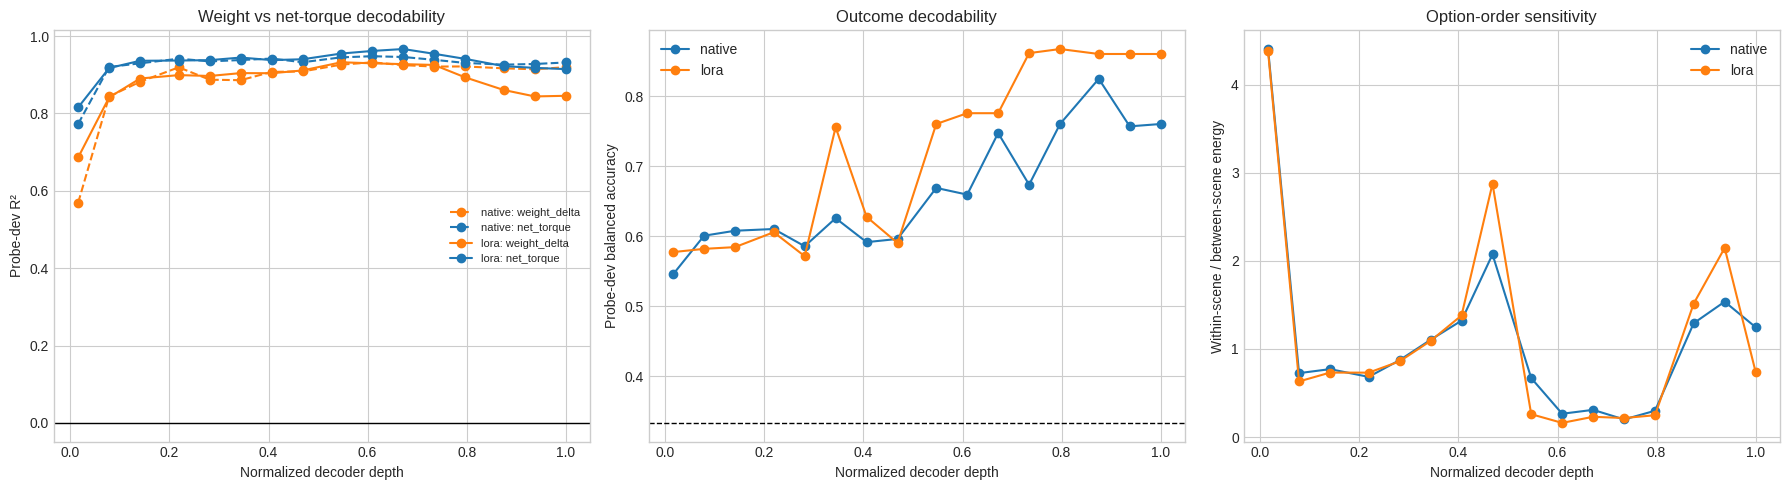

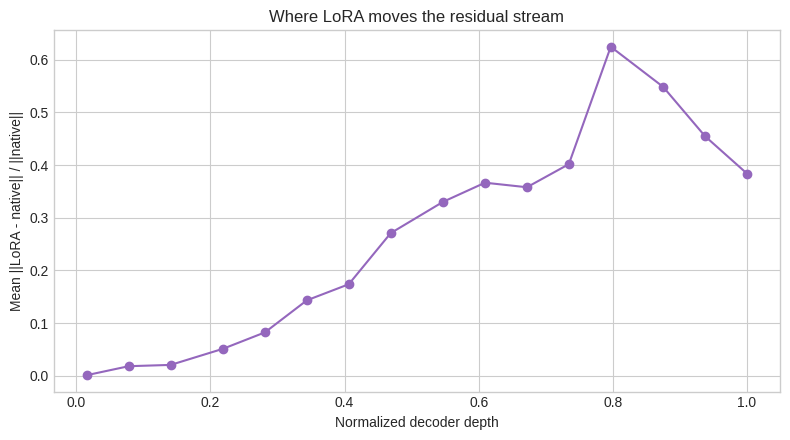

Frozen hypotheses: /content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_mechanism_discovery_v1/FROZEN_MECHANISM_HYPOTHESES.json


,site,model,target,layer_position,layer_index,normalized_depth,alpha,train_scenes,dev_scenes,dev_r2,dev_mae,dev_spearman,dev_balanced_accuracy,dev_macro_f1
0,LoRA net torque,lora,net_torque,10,42,0.6719,100.0,985,108,0.9665,1.5389,0.9831,NaN,NaN
1,LoRA outcome,lora,outcome,12,50,0.7969,100.0,985,108,NaN,NaN,NaN,0.8674,0.8216
2,Native weight,native,weight_delta,9,38,0.6094,100.0,985,108,0.9320,0.4495,0.9702,NaN,NaN


In [16]:
%%cell_progress 15/16 Freeze discovery layers, probes, and diagnostic figures
cell_stage('Selecting LoRA torque and outcome layers on probe_dev')
def best_row(frame, model_name, target, metric):
    current = frame[
        (frame['model'] == model_name) & (frame['target'] == target)
    ].copy()
    return (
        current.sort_values(
            [metric, 'normalized_depth'], ascending=[False, True]
        ).iloc[0].to_dict()
    )

torque_choice = best_row(
    continuous_probes, 'lora', 'net_torque', 'dev_r2'
)
outcome_choice = best_row(
    classification_probes, 'lora', 'outcome', 'dev_balanced_accuracy'
)
base_weight_choice = best_row(
    continuous_probes, 'native', 'weight_delta', 'dev_r2'
)

net_curve = continuous_probes[
    continuous_probes['target'] == 'net_torque'
].pivot(index='layer_index', columns='model', values='dev_r2')
weight_curve = continuous_probes[
    continuous_probes['target'] == 'weight_delta'
].pivot(index='layer_index', columns='model', values='dev_r2')
relocation = pd.DataFrame({
    'layer_index': layer_indices,
    'normalized_depth': normalized_depths,
    'net_torque_gain': [
        float(net_curve.loc[index, 'lora'] - net_curve.loc[index, 'native'])
        for index in layer_indices
    ],
    'weight_delta_gain': [
        float(weight_curve.loc[index, 'lora'] - weight_curve.loc[index, 'native'])
        for index in layer_indices
    ],
})
relocation['torque_specific_gain'] = (
    relocation['net_torque_gain']
    - relocation['weight_delta_gain'].clip(lower=0)
)
relocation_choice = relocation.sort_values(
    ['torque_specific_gain', 'normalized_depth'], ascending=[False, True]
).iloc[0].to_dict()
relocation.to_csv(ANALYSIS_DIR / 'torque_vs_weight_relocation.csv', index=False)

cell_stage('Refitting and saving frozen LoRA probes')
def fit_and_save_probe(choice, target, kind, destination):
    layer_position = int(choice['layer_position'])
    X_train = lora_main[train_mask, layer_position, :]
    y = main_metadata[target].to_numpy()
    if kind == 'continuous':
        estimator = make_pipeline(
            StandardScaler(),
            Ridge(alpha=PROBE_ALPHA, solver='lsqr', max_iter=5000),
        )
    else:
        estimator = make_pipeline(
            StandardScaler(),
            RidgeClassifier(
                alpha=PROBE_ALPHA, solver='lsqr', class_weight='balanced',
            ),
        )
    estimator.fit(X_train, y[train_mask])
    joblib.dump(estimator, destination)
    return {
        'path': str(destination),
        'sha256': sha256_file(destination),
        'target': target,
        'kind': kind,
        'layer_position': layer_position,
        'layer_index': int(choice['layer_index']),
        'normalized_depth': float(choice['normalized_depth']),
        'fit_split': 'probe_train',
        'selection_split': 'probe_dev',
        'probe_test_used': False,
    }

torque_probe_manifest = fit_and_save_probe(
    torque_choice, 'net_torque', 'continuous',
    PROBE_DIR / 'lora_net_torque_probe.joblib',
)
outcome_probe_manifest = fit_and_save_probe(
    outcome_choice, 'outcome', 'classification',
    PROBE_DIR / 'lora_outcome_probe.joblib',
)

frozen_hypotheses = {
    'schema_version': 'qwen27b-base-lora-frozen-mechanism-hypotheses-1.0',
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_manifest_sha256': sha256_file(ADAPTER_MANIFEST_PATH),
    'discovery_manifest_sha256': sha256_file(DISCOVERY_MANIFEST_PATH),
    'fit_split': 'probe_train',
    'selection_split': 'probe_dev',
    'probe_test_used_for_layer_selection': False,
    'sft_seen_probe_dev_scenes': 0,
    'fixed_probe_alpha': PROBE_ALPHA,
    'lora_net_torque_layer': torque_choice,
    'lora_outcome_layer': outcome_choice,
    'native_weight_layer': base_weight_choice,
    'torque_specific_relocation_layer': relocation_choice,
    'saved_probes': [torque_probe_manifest, outcome_probe_manifest],
    'claims_allowed_now': [
        'train/dev decodability',
        'native-versus-LoRA representational movement',
        'candidate mechanism sites for preregistered causal testing',
    ],
    'claims_not_allowed_now': [
        'the probe direction is causally used',
        'LoRA repaired a torque circuit',
        'the mechanism generalizes beyond Dataset v1',
    ],
}
FROZEN_HYPOTHESES_PATH = OUTPUT_ROOT / 'FROZEN_MECHANISM_HYPOTHESES.json'
write_json_atomic(FROZEN_HYPOTHESES_PATH, frozen_hypotheses)

cell_stage('Rendering compact discovery figures')
plt.style.use('seaborn-v0_8-whitegrid')
figure, axes = plt.subplots(1, 3, figsize=(18, 5))
for model_name, linestyle in (('native', '--'), ('lora', '-')):
    for target, color in (('weight_delta', 'tab:orange'), ('net_torque', 'tab:blue')):
        frame = continuous_probes[
            (continuous_probes['model'] == model_name)
            & (continuous_probes['target'] == target)
        ]
        axes[0].plot(
            frame['normalized_depth'], frame['dev_r2'],
            marker='o', linestyle=linestyle, color=color,
            label=f'{model_name}: {target}',
        )
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_title('Weight vs net-torque decodability')
axes[0].set_xlabel('Normalized decoder depth')
axes[0].set_ylabel('Probe-dev R²')
axes[0].legend(fontsize=8)

for model_name in ('native', 'lora'):
    frame = classification_probes[
        (classification_probes['model'] == model_name)
        & (classification_probes['target'] == 'outcome')
    ]
    axes[1].plot(
        frame['normalized_depth'], frame['dev_balanced_accuracy'],
        marker='o', label=model_name,
    )
axes[1].axhline(1 / 3, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Outcome decodability')
axes[1].set_xlabel('Normalized decoder depth')
axes[1].set_ylabel('Probe-dev balanced accuracy')
axes[1].legend()

for model_name in ('native', 'lora'):
    frame = permutation_dispersion[permutation_dispersion['model'] == model_name]
    axes[2].plot(
        frame['normalized_depth'], frame['within_to_between_ratio'],
        marker='o', label=model_name,
    )
axes[2].set_title('Option-order sensitivity')
axes[2].set_xlabel('Normalized decoder depth')
axes[2].set_ylabel('Within-scene / between-scene energy')
axes[2].legend()
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / 'base_vs_lora_mechanism_discovery.png',
    dpi=180, bbox_inches='tight',
)
plt.show()

figure, axis = plt.subplots(figsize=(8, 4.5))
shift_dev = representation_shift[
    representation_shift['subset'] == 'probe_dev'
]
axis.plot(
    shift_dev['normalized_depth'], shift_dev['mean_relative_delta_norm'],
    marker='o', color='tab:purple',
)
axis.set_xlabel('Normalized decoder depth')
axis.set_ylabel('Mean ||LoRA - native|| / ||native||')
axis.set_title('Where LoRA moves the residual stream')
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / 'native_lora_residual_shift.png',
    dpi=180, bbox_inches='tight',
)
plt.show()

print('Frozen hypotheses:', FROZEN_HYPOTHESES_PATH)
display(pd.DataFrame([
    {'site': 'LoRA net torque', **torque_choice},
    {'site': 'LoRA outcome', **outcome_choice},
    {'site': 'Native weight', **base_weight_choice},
]).round(4))


In [17]:
%%cell_progress 16/16 Verify the discovery package and state the next causal gate
cell_stage('Checking every required output')
required_outputs = (
    ANALYSIS_DIR / 'test_set_coverage_audit.json',
    ANALYSIS_DIR / 'test_scene_coverage_table.csv',
    OUTPUT_ROOT / 'discovery_design.json',
    DISCOVERY_MANIFEST_PATH,
    BASE_CAPTURE_DIR / 'capture_config.json',
    BASE_CAPTURE_DIR / 'capture_summary.json',
    BASE_CAPTURE_DIR / 'capture_index.jsonl',
    LORA_CAPTURE_DIR / 'capture_config.json',
    LORA_CAPTURE_DIR / 'capture_summary.json',
    LORA_CAPTURE_DIR / 'capture_index.jsonl',
    ANALYSIS_DIR / 'train_dev_behavior.csv',
    ANALYSIS_DIR / 'behavior_summary.csv',
    ANALYSIS_DIR / 'decision_margin_dependency.csv',
    ANALYSIS_DIR / 'native_lora_representation_shift.csv',
    ANALYSIS_DIR / 'permutation_dispersion.csv',
    ANALYSIS_DIR / 'continuous_probe_curves.csv',
    ANALYSIS_DIR / 'classification_probe_curves.csv',
    ANALYSIS_DIR / 'torque_vs_weight_relocation.csv',
    PROBE_DIR / 'lora_net_torque_probe.joblib',
    PROBE_DIR / 'lora_outcome_probe.joblib',
    FROZEN_HYPOTHESES_PATH,
    FIGURE_DIR / 'base_vs_lora_mechanism_discovery.png',
    FIGURE_DIR / 'native_lora_residual_shift.png',
)
missing = [str(file_path) for file_path in required_outputs if not file_path.is_file()]
assert not missing, 'Missing required outputs:\n' + '\n'.join(missing)

assert set(main_metadata['split']) == {'probe_train', 'probe_dev'}
assert 'probe_test' not in set(main_metadata['split'])
for capture_dir in (BASE_CAPTURE_DIR, LORA_CAPTURE_DIR):
    summary = json.loads(
        (capture_dir / 'capture_summary.json').read_text(encoding='utf-8')
    )
    assert summary['probe_test_examples'] == 0
    assert summary['allowed_splits'] == ['probe_dev', 'probe_train']

completion = {
    'schema_version': 'qwen27b-base-lora-mechanism-discovery-complete-1.0',
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_dir': str(ADAPTER_DIR),
    'adapter_manifest_sha256': sha256_file(ADAPTER_MANIFEST_PATH),
    'main_scene_count': len(main_metadata),
    'probe_train_scenes': int(train_mask.sum()),
    'probe_dev_scenes': int(dev_mask.sum()),
    'probe_test_model_prompts': 0,
    'frozen_hypotheses': str(FROZEN_HYPOTHESES_PATH),
    'required_outputs': [str(file_path) for file_path in required_outputs],
    'next_gate': (
        'Freeze these hypotheses and run preregistered activation patching on '
        'a newly generated independently seeded/style-shifted blind set.'
    ),
}
write_json_atomic(OUTPUT_ROOT / 'RUN_COMPLETE.json', completion)
print('Mechanism discovery complete:', OUTPUT_ROOT / 'RUN_COMPLETE.json')
print()
print('Interpretation:')
print('- This run can show where torque/weight/outcome information becomes linearly decodable.')
print('- It can show how LoRA changes those depth profiles and option-order sensitivity.')
print('- It cannot yet prove that the selected representation causes the answer.')
print()
print('Next notebook: frozen-site causal patching on a new blind confirmatory dataset.')


Verify the discovery package and state the next causal gate:  94%|#########3| 15/16 [00:00<?, ?cell/s]

Mechanism discovery complete: /content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_mechanism_discovery_v1/RUN_COMPLETE.json

Interpretation:
- This run can show where torque/weight/outcome information becomes linearly decodable.
- It can show how LoRA changes those depth profiles and option-order sensitivity.
- It cannot yet prove that the selected representation causes the answer.

Next notebook: frozen-site causal patching on a new blind confirmatory dataset.
